```{contents}
:local:
:depth: 2
```

# 4.2 Optimization in Reduced Spaces

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 10, Lesson 1: *Dimensionality Challenges*
- Module 10, Lesson 2: *Dimensionality Reduction: Principal Component Analysis*
- Module 10, Lesson 3: *Principal Component Analysis Example*
- Module 10, Lesson 4: *Regression in Reduced Spaces*
- Module 10, Lesson 5: *Optimization in Reduced Spaces*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Distinguish feature selection from dimensionality reduction, and recognize when measured variables are redundant.
- Derive principal component analysis as a constrained optimization problem and interpret its Lagrange multipliers.
- Fit a regression model in a reduced space (principal component regression, partial least squares) and explain why it is better conditioned than a full-space fit on correlated inputs.
- Optimize a reduced-space model, map the solution back to the original variables, and check that the back-mapped point is valid.
- Explain how a reduced space can encode the constraints that the data obeyed, and run an adaptive optimization in that space.
:::

In Topic 4.1 we dealt with data that were incomplete, noisy or wrong, and in this topic we will deal with data that are redundant. The variables in a historian are rarely independent (e.g. the three flow meters on one stack all measure the load), so the *true* dimensionality of the data is lower than the number of columns. If we can find it, then our models will be better conditioned, and we will be able to optimize over a few meaningful directions.

The tools that we use to find it are principal component analysis (PCA) and its regression relatives, principal component regression (PCR) and partial least squares (PLS). These are covered in depth in DA4CHE, in Topic 5.2, *Dimensionality Reduction*, for PCA (covariance, eigendecomposition, scree plots, reconstruction, kernel PCA), and in Topics 2.4–2.5, *High-dimensional Data* and *High-dimensional Regression*, for scaling, forward selection, PCR and PLS (https://www.medford.chbe.gatech.edu/DA4CHE/). Here we will only recap them briefly, and we will spend most of the topic on PCA as an optimization problem and on optimization in the reduced space.

## Too many dimensions

Real undesigned data sets in engineering usually have tens to hundreds of variables, and these are hard to visualize, since a scatter plot of the output shows its range but does not show how the output depends on ten inputs. It is also unlikely that every input is independent and that every input matters. Some inputs vary together because they are correlated, like the temperatures at different points of one reactor, or the mean radius, perimeter and area of a tumor in the breast-cancer data set that is used in the course notebook, and we can find these pairs with a correlation heat map. Other inputs have no effect on the output, like biomarkers that are unrelated to a patient's condition. This creates two opportunities:

- **Feature selection** removes redundant or useless variables. Regularization does this: the LASSO of Topic 3.5 drives the coefficients of unhelpful inputs to zero. So do forward selection and backward elimination, adding or removing one input at a time until the validation error goes up (DA4CHE Topic 2.5).
- **Dimensionality reduction** re-expresses the information in fewer, new variables. The measured inputs may all be useful and still not be the right inputs: what drives the output may be combinations of them.

The lectures illustrate the second case with an example from Shlens's tutorial on PCA. Suppose that a ball on a spring oscillates along one axis, but that we do not know the physics, so the only thing we can do is film it with three low-resolution cameras that are placed at different angles. The 72,000 frames give six columns (two per camera) which are all noisy and strongly correlated, although they describe a one-dimensional motion. If a dimensionality-reduction method works, it should be able to recover a single variable from the six.

The stack historian from Topic 4.1 has the same structure, since the hydrogen, water and oxygen flow meters and the temperature probe all respond to one thing, which is the load.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from _lib import electrolyzer as el
from _lib import part4a_tools as t4

log = t4.stack_log()
sensors = ['h2_kg_h', 'water_kg_h', 'o2_kg_h', 'temp_C']
R = log[sensors].corr()
print(R.round(3).to_string())
off = R.values[np.triu_indices(4, 1)]
print(f"smallest pairwise correlation among the four sensors: {off.min():.3f}")

            h2_kg_h  water_kg_h  o2_kg_h  temp_C
h2_kg_h       1.000       0.999    0.998   0.943
water_kg_h    0.999       1.000    0.998   0.942
o2_kg_h       0.998       0.998    1.000   0.942
temp_C        0.943       0.942    0.942   1.000
smallest pairwise correlation among the four sensors: 0.942


We can see that the flow meters are correlated with each other at 0.998 or more, and the temperature is correlated with each of them at 0.942, so we have four columns but only one underlying variable. This means that a regression on all four columns has to divide one effect among nearly identical columns, which is numerically fragile.

:::{exercise}
:label: ex-t42-redundant-sensors

Regress the power meter reading (`power_MW`) on the four sensors with ordinary least squares, first using all 400 records and then using only the first 40. Compare the four coefficients between the two fits. Then regress power on the hydrogen meter alone. Which model would you trust to extrapolate, and why?
:::

## PCA as an optimization problem

PCA finds a new set of orthogonal axes, called the **principal components**, which are ordered so that the first one captures as much of the variance in the data as possible, the second one captures as much of what remains as possible, and so on. It is an unsupervised method, i.e. it only looks at the inputs and not at any output. Since the variance depends on the units, the data are first centered and usually standardized (i.e. each column is scaled to unit variance), because otherwise a variable that is measured in large numbers will dominate for no physical reason.

It turns out that the first principal component is the solution of an optimization problem. Let $X$ be the $N \times d$ matrix of centered, scaled data, and let $C = X^\top X/(N-1)$ be its covariance matrix. If we project the data onto a unit vector $p$ we get the scores $t = Xp$, and the variance of the scores is $p^\top C p$. The direction of greatest variance solves

$$
\max_{p} \; p^\top C p \quad \text{s.t.} \quad p^\top p = 1.
$$

We need the constraint because otherwise the variance would grow without bound as $p$ is lengthened. The squared length of each centered point splits into its squared projection on $p$ plus its squared distance from the axis, so maximizing the projected variance is the same as minimizing the sum of squared distances from the points to the axis, which is the picture of PCA used in the lectures. This is an equality-constrained NLP of the same kind that we solved in Topic 2.2. The Lagrangian is $\mathcal{L}(p, \lambda) = p^\top C p - \lambda (p^\top p - 1)$, and stationarity gives

$$
\nabla_p \mathcal{L} = 2Cp - 2\lambda p = 0 \quad\Longrightarrow\quad C p = \lambda p.
$$

This tells us that the KKT points are the eigenvectors of $C$, and at each one the objective is equal to $p^\top C p = \lambda p^\top p = \lambda$. Therefore, the maximum variance is the largest eigenvalue, and it is attained by the corresponding eigenvector. The Lagrange multiplier also has a direct meaning: **the multiplier of the unit-length constraint is the variance captured by that component.** The second component solves the same problem with the extra constraint $p^\top p_1 = 0$, which gives the eigenvector of the second-largest eigenvalue, and so on. If we collect the first $r$ eigenvectors as the columns of the **loading** matrix $P$ ($d \times r$), then the **scores** are $T = XP$ ($N \times r$), and the data are approximated by

$$
X \approx T P^\top, \qquad \hat X = T P^\top + \bar x,
$$

where the mean $\bar x$ is added back after a centered PCA. When the signal-to-noise ratio is high the residual $X - TP^\top$ is mostly noise, so PCA also acts as a noise filter. PCA is also helpful for missing data, because a few missing values will barely move directions that are determined by many records, and EM-style algorithms can alternate between estimating the components and filling in the gaps from the current estimate.

The next cell checks the derivation on the four sensors by computing the eigenvalues of $C$, and by solving the constrained problem directly with SLSQP, which is the general NLP method from Topic 2.1.

In [2]:
from scipy.optimize import minimize

Z = (log[sensors] - log[sensors].mean()) / log[sensors].std(ddof=1)
C = np.cov(Z.values.T)
lam, P = np.linalg.eigh(C)
lam, P = lam[::-1], P[:, ::-1]                      # largest first
p1 = P[:, 0] * np.sign(P[0, 0])
print("eigenvalues (= Lagrange multipliers = variance along each PC):", lam.round(4))
print("fraction of variance:", (lam / lam.sum()).round(4))
print("first loading vector:", p1.round(3))

rng = np.random.default_rng(0)
sol = minimize(lambda p: -p @ C @ p, rng.standard_normal(4), method='SLSQP',
               constraints=[{'type': 'eq', 'fun': lambda p: p @ p - 1}])
p_nlp = sol.x * np.sign(sol.x[0])
print(f"SLSQP on max p'Cp s.t. p'p = 1: objective {-sol.fun:.4f}, |p - p1| = {np.linalg.norm(p_nlp - p1):.1e}")
t1 = Z.values @ p1
print(f"correlation of the first score with the true load: {np.corrcoef(t1, log.load)[0, 1]:.4f}")

eigenvalues (= Lagrange multipliers = variance along each PC): [3.9115e+00 8.5300e-02 2.1000e-03 1.1000e-03]
fraction of variance: [9.779e-01 2.130e-02 5.000e-04 3.000e-04]
first loading vector: [0.504 0.504 0.504 0.489]
SLSQP on max p'Cp s.t. p'p = 1: objective 3.9115, |p - p1| = 1.1e-06
correlation of the first score with the true load: 0.9966


| Quantity | Value |
|---|---|
| Largest eigenvalue of $C$ (the Lagrange multiplier) | 3.9115 |
| Fraction of variance on the first component | 0.9779 |
| SLSQP objective from a random start | 3.9115 |
| Distance between the SLSQP direction and $p_1$ | 1.1e-06 |
| Loading on each flow meter | 0.504 |
| Loading on the temperature probe | 0.489 |
| Correlation of the first score with the true load | 0.9966 |

The first component explains almost all of the variance of the four standardized sensors, and starting SLSQP from a random direction gives the same objective and the same direction (to within $10^{-6}$). The loading vector weights the flow meters equally and the temperature slightly less, and the first score correlates almost perfectly with the true load, so PCA has recovered the hidden variable from four noisy, redundant measurements in the same way that it did for the ball on the spring.

The key decision in PCA is how many components to keep. The ten-dimensional example from the lectures, which is adapted from the course notebook `High Dimensional, Unstructured Data analysis.ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT), shows the usual workflow on 100 samples of ten chemical properties, where each sample is labeled with a product grade from 0 to 3.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


explained variance ratio: [0.416 0.339 0.16  0.02  0.016]  cumulative: [0.416 0.755 0.915 0.935 0.952]


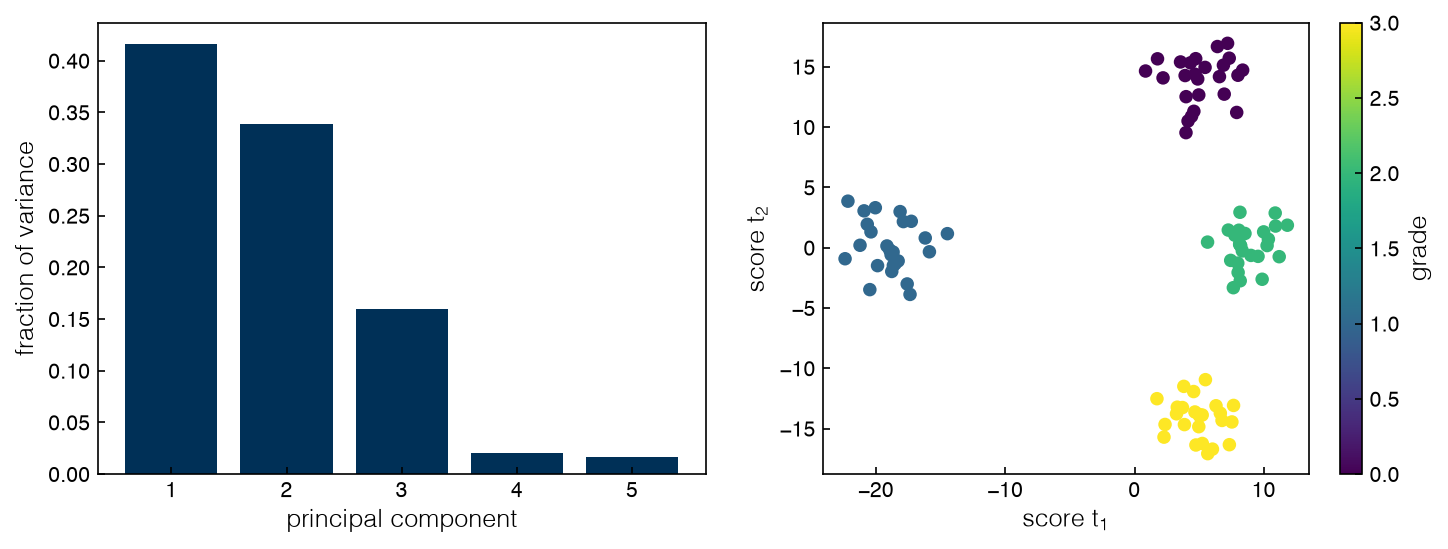

In [3]:
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA

X10, grade = make_blobs(n_features=10, n_samples=100, centers=4, random_state=4, cluster_std=2)
pca10 = PCA(n_components=5).fit(X10)
r = pca10.explained_variance_ratio_
print("explained variance ratio:", r.round(3), " cumulative:", r.cumsum().round(3))
S10 = pca10.transform(X10)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(range(1, 6), r)
axes[0].set_xlabel('principal component'); axes[0].set_ylabel('fraction of variance')
sc = axes[1].scatter(S10[:, 0], S10[:, 1], c=grade, cmap='viridis', s=30)
axes[1].set_xlabel('score $t_1$'); axes[1].set_ylabel('score $t_2$')
fig.colorbar(sc, ax=axes[1], label='grade');

| Component | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Explained variance ratio | 0.416 | 0.339 | 0.16 | 0.02 | 0.016 |
| Cumulative | 0.416 | 0.755 | 0.915 | 0.935 | 0.952 |

Three components explain most of the variance, after which the curve flattens out. The usual rule is to keep adding components until the explained variance reaches a plateau, using whatever is known about the noise to decide where the plateau starts. For example, if about 10% of the variance is noise, three components will be enough. The **score plot** of the first two components separates the four grades into clusters, even though no single input shows them, whereas for scaled data without structure the score plot would be a shapeless cloud around the origin. The loadings, which are the weights of each original variable in each component, reveal which inputs move together, and plotting the loadings as arrows gives the loadings plot that is used below for the cheddar data. DA4CHE Topic 5.2 shows the scree plot and other criteria.

:::{exercise}
:label: ex-t42-second-multiplier

Add the constraint $p^\top p_1 = 0$ to the SLSQP problem and solve it. Check that the objective equals the second eigenvalue. Then interpret the second component from its loading vector: which sensor dominates it, and what physical effect, other than load, could it be measuring?
:::

## A worked example: cheddar cheese

:::{admonition} Adapted material
:class: note
This section and the next two adapt the course notebook `Regression and Optimization with transformed reduced spaces (PCR, PLS).ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT) and its data files `cheddar-cheese.xlsx` and `cheddar-cheese2.xlsx` (stored here as CSV). The notebook's Pyomo least-squares fits are replaced by `numpy` least squares, which gives the same coefficients; Pyomo is kept for the constrained optimization.
:::

The main example in the lectures is a classic small data set of 30 mature cheddars from the LaTrobe Valley, Australia. There are three inputs, which are the concentrations of acetic acid and hydrogen sulfide (recorded as natural logarithms) and of lactic acid, and the output is the taste score from a panel. The data were popularized by Moore and McCabe's statistics textbook, and they are also available as `cheddar` in the R package `faraway`. We want to find the composition that maximizes taste.

This data set was not designed. These are 30 cheeses as they came, and thirty samples is enough to fit a quadratic in three inputs, but not by much.

The course uses two versions of the data: the original data, and a modified version with the same taste scores in which the inputs were altered so that they are exactly redundant. We will follow the lectures and use the modified version, after first comparing it with the original. Scaling the inputs to z-scores is important in this case, because PCA is a variance-based method and the hydrogen sulfide concentration varies over a much wider numerical range than the lactic acid concentration.

original: correlations Acetic-H2S 0.62, Acetic-Lactic 0.60, H2S-Lactic 0.64
original: explained variance ratio [0.7481 0.1337 0.1182]
modified: correlations Acetic-H2S 0.62, Acetic-Lactic 0.91, H2S-Lactic 0.89
modified: explained variance ratio [0.8731 0.1269 0.    ]
modified file: Lactic = -0.1265 + 0.2261 Acetic + 0.0547 H2S, max residual 6.0e-09
loadings (rows PC1, PC2; columns Acetic, H2S, Lactic):
[[ 0.5589  0.5531  0.6178]
 [-0.691   0.7225 -0.0217]]


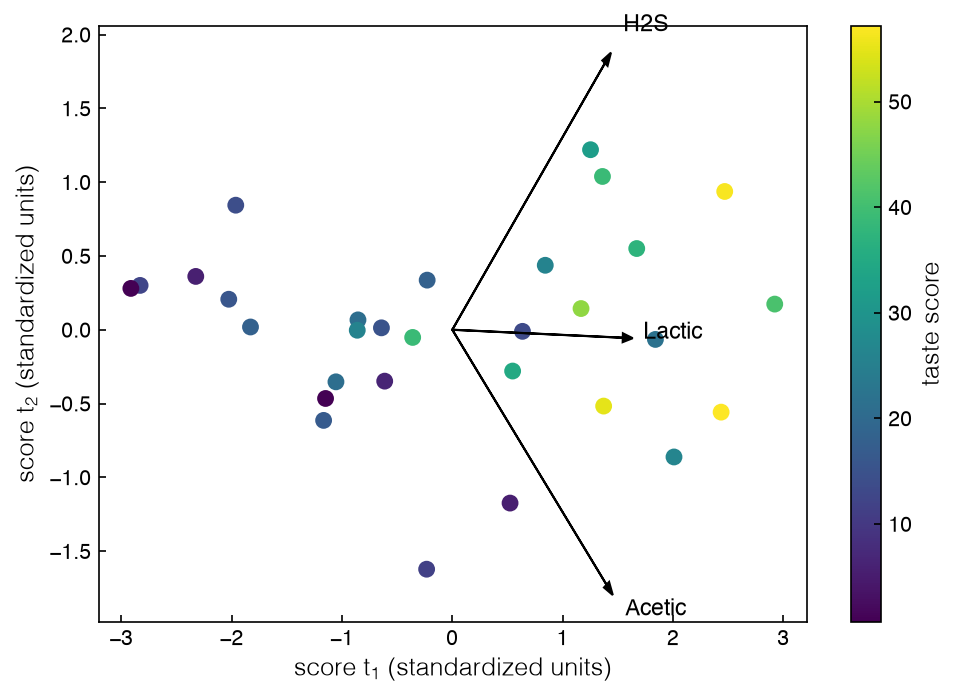

In [4]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

orig = pd.read_csv('data/cheddar-cheese.csv')
mod = pd.read_csv('data/cheddar-cheese2.csv')
xcols = ['Acetic', 'H2S', 'Lactic']
for lab, df in [('original', orig), ('modified', mod)]:
    c = df[xcols].corr().values
    print(f"{lab:8s}: correlations Acetic-H2S {c[0,1]:.2f}, Acetic-Lactic {c[0,2]:.2f}, H2S-Lactic {c[1,2]:.2f}")
    pca_all = PCA().fit(StandardScaler().fit_transform(df[xcols]))
    print(f"{lab:8s}: explained variance ratio {pca_all.explained_variance_ratio_.round(4)}")

A1 = np.column_stack([np.ones(30), mod[['Acetic', 'H2S']]])
coef, *_ = np.linalg.lstsq(A1, mod.Lactic, rcond=None)
print(f"modified file: Lactic = {coef[0]:.4f} + {coef[1]:.4f} Acetic + {coef[2]:.4f} H2S, "
      f"max residual {np.abs(mod.Lactic - A1 @ coef).max():.1e}")

sx = StandardScaler().fit(mod[xcols])
sy = StandardScaler().fit(mod[['Taste']])
X = sx.transform(mod[xcols])
y = sy.transform(mod[['Taste']]).ravel()
pca = PCA(n_components=2).fit(X)
T = pca.transform(X)
print("loadings (rows PC1, PC2; columns Acetic, H2S, Lactic):")
print(pca.components_.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(T[:, 0], T[:, 1], c=mod.Taste, cmap='viridis', s=50)
for j, nm in enumerate(xcols):
    ax.arrow(0, 0, 2.5 * pca.components_[0, j], 2.5 * pca.components_[1, j], color='k', head_width=0.06)
    ax.text(2.8 * pca.components_[0, j], 2.8 * pca.components_[1, j], nm, fontsize=11)
ax.set_xlabel('score $t_1$ (standardized units)')
ax.set_ylabel('score $t_2$ (standardized units)')
fig.colorbar(sc, label='taste score');

| Data | Corr. Acetic–H2S | Corr. Acetic–Lactic | Corr. H2S–Lactic | Variance, PC1 | Variance, PC2 | Variance, PC3 |
|---|---|---|---|---|---|---|
| original | 0.62 | 0.60 | 0.64 | 0.7481 | 0.1337 | 0.1182 |
| modified | 0.62 | 0.91 | 0.89 | 0.8731 | 0.1269 | 0 |

| Loading | Acetic | H2S | Lactic |
|---|---|---|---|
| PC1 | 0.5589 | 0.5531 | 0.6178 |
| PC2 | -0.691 | 0.7225 | -0.0217 |

The table shows that the inputs in the original data are moderately correlated, and that the variance is spread over all of the components, so there is real variation in the third direction. The modified file is different. Here lactic acid is strongly correlated with the other inputs, and the first two components explain everything while the last one explains exactly zero. This happens because lactic acid is an exact linear combination of acetic acid and hydrogen sulfide (with a residual of $6 \times 10^{-9}$), which means that the inputs lie on a plane.

The figure is a **score plot** with the loadings drawn as arrows (also called a biplot). The first component gives similar weights to all three inputs, so we can think of this component as a measure of the overall chemical strength, and the taste rises as we move along the first component. The second component contrasts acetic acid with hydrogen sulfide. If there were clusters or outliers in the data, we would be able to see them in the score plot.

:::{exercise}
:label: ex-t42-original-cheddar

Repeat the score plot for the original data, `orig`, keeping two components. Compute the reconstruction error $\lVert X - \hat X \rVert$ of each sample and list the three cheeses that the two-component model represents worst. Are they unusual in taste as well?
:::

## Regression in reduced spaces

In the lectures the same model is fit in two ways. **Multivariate regression** treats the $K = 3$ inputs as independent and fits a quadratic in all of the inputs, $\hat y = b_0 + \sum_j b_j x_j + \sum_j b_{jj} x_j^2$, which has seven parameters. **Principal component regression** first projects the $N \times K$ inputs onto $A = 2$ components to get the $N \times A$ score matrix $T$, and then fits the same form in the scores, $\hat y = d_0 + \sum_a d_a t_a + \sum_a d_{aa} t_a^2$, which has five parameters. Both fits are linear least squares problems, so we can solve them directly and look at how well conditioned each model is.

In [5]:
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict, LeaveOneOut

def quad_features(V):
    return np.column_stack([np.ones(len(V)), V, V ** 2])

F_full, F_pcr = quad_features(X), quad_features(T)
b_full, *_ = np.linalg.lstsq(F_full, y, rcond=None)
b_pcr, *_ = np.linalg.lstsq(F_pcr, y, rcond=None)
mse = lambda F, b: np.mean((F @ b - y) ** 2)
print(f"full space: cond = {np.linalg.cond(F_full):.1e}, training MSE = {mse(F_full, b_full):.4f}, "
      f"largest |coefficient| = {np.abs(b_full).max():.1e}")
print(f"PCR       : cond = {np.linalg.cond(F_pcr):.1e}, training MSE = {mse(F_pcr, b_pcr):.4f}, "
      f"coefficients {b_pcr.round(4)}")
print(f"original data, full space: cond = {np.linalg.cond(quad_features(StandardScaler().fit_transform(orig[xcols]))):.1e}")

loo = LeaveOneOut()
for lab, F in [('full quadratic', F_full), ('PCR quadratic', F_pcr)]:
    yp = cross_val_predict(LinearRegression(fit_intercept=False), F, y, cv=loo)
    print(f"{lab:15s}: leave-one-out MSE = {np.mean((yp - y) ** 2):.4f}")
for a in [1, 2]:
    yp = cross_val_predict(PLSRegression(n_components=a, scale=False), X, y, cv=loo).ravel()
    print(f"PLS, {a} latent variable{'s' if a > 1 else ''}: leave-one-out MSE = {np.mean((yp - y) ** 2):.4f}")

full space: cond = 2.2e+08, training MSE = 0.3890, largest |coefficient| = 3.1e+06
PCR       : cond = 8.0e+00, training MSE = 0.3909, coefficients [ 0.0154  0.472   0.2812  0.0248 -0.2109]
original data, full space: cond = 5.3e+00
full quadratic : leave-one-out MSE = 0.6022
PCR quadratic  : leave-one-out MSE = 0.5533
PLS, 1 latent variable: leave-one-out MSE = 0.5108
PLS, 2 latent variables: leave-one-out MSE = 0.4955


| Model | Condition number | Largest coefficient | Training MSE | Leave-one-out MSE |
|---|---|---|---|---|
| Full-space quadratic | 2.2e+08 | 3.1e+06 | 0.3890 | 0.6022 |
| PCR quadratic | 8.0e+00 | 0.472 | 0.3909 | 0.5533 |
| Full-space quadratic, original data | 5.3e+00 | | | |
| PLS, 1 latent variable | | | | 0.5108 |
| PLS, 2 latent variables | | | | 0.4955 |

If we looked at the training error alone we would have no reason to prefer one model over the other, since both fit the data about as well as in the course notebook. There is a big difference in the conditioning, though. The design matrix in the full space is nearly singular, and the largest coefficient in the model is in the millions. This happens because huge multiples of the redundant combination of inputs can be added to the fit, since these multiples cancel on every data point. PCR does not have this problem, and has a small condition number and coefficients of order 1. When the full-space model is fit to the original data it is well behaved, which tells us that the trouble comes from the redundancy in the inputs and not from the regression. In addition, PCR predicts better than the full model under leave-one-out cross-validation.

**Partial least squares** (PLS, or projection to latent structures) takes this idea one step further. When PCA chooses its directions the only thing that is considered is the variance of the inputs, whether or not this variance is relevant to the output. PLS reduces both the input and output spaces, so that the input directions are chosen to best explain the outputs. In this example even a linear PLS model with one latent variable predicts better than either of the quadratic models, and if we use two latent variables there is a small further improvement. The details of how the PLS weights and loadings are computed can be found in DA4CHE Topic 2.5.

Regression in a reduced space has fewer parameters, uses orthogonal inputs, and fits less of the noise. In this example we do not lose anything when we reconstruct the inputs from two components, $\hat X = TP^\top + \bar x$. However, if we keep fewer components than the data need we will lose detail, just like an image that is compressed with too few components loses resolution.

:::{exercise}
:label: ex-t42-pcr-components

Fit the PCR quadratic with one component instead of two and compare its leave-one-out MSE with the values above. Then add a cross term $t_1 t_2$ to the two-component model. Does either change justify its effect on the number of parameters, given only 30 cheeses?
:::

## Optimization in reduced spaces

Now we can use each model to choose the best cheese. The obvious formulation is to maximize the fitted taste in the full space over the box of observed input ranges, and since the quadratic is separable we can get the exact maximum by checking the endpoints and stationary point for each coordinate.

In [6]:
to_taste = lambda v: v * sy.scale_[0] + sy.mean_[0]
to_x = lambda Zs: sx.inverse_transform(np.atleast_2d(Zs))[0]
lo, hi = X.min(0), X.max(0)

def best_in_interval(bl, bs, a, b):
    """Maximize bl*z + bs*z^2 over [a, b] exactly."""
    cands = [a, b] + ([-bl / (2 * bs)] if bs < 0 and a < -bl / (2 * bs) < b else [])
    return max(cands, key=lambda z: bl * z + bs * z * z)

z_full = np.array([best_in_interval(b_full[1 + j], b_full[4 + j], lo[j], hi[j]) for j in range(3)])
print(f"full-space optimum in the data box: predicted taste {to_taste(quad_features(z_full[None])[0] @ b_full):.3g}, "
      f"x = {to_x(z_full).round(3)}")
dist = np.linalg.norm(z_full - pca.inverse_transform(pca.transform(z_full[None]))[0])
print(f"distance of that point from the plane of the data (standardized units): {dist:.3f}")
print(f"largest distance of any cheese from the plane: "
      f"{np.linalg.norm(X - pca.inverse_transform(T), axis=1).max():.1e}")

full-space optimum in the data box: predicted taste 1.78e+08, x = [4.479 2.997 1.832]
distance of that point from the plane of the data (standardized units): 2.835
largest distance of any cheese from the plane: 2.2e-08


The full-space model predicts a taste of $1.8 \times 10^{8}$, on a scale where the best observed value is 57.2! The optimizer has found the corner of the box (lowest acetic acid, lowest hydrogen sulfide, highest lactic acid) where the huge, cancelling coefficients no longer cancel. This corner is inside the box, but it is 2.84 standardized units away from the plane where all of the cheeses lie, and no cheese is farther than about $10^{-8}$ from it. In general, correlated data only occupy a thin slice of their bounding box, and an optimizer will find the place where a model is most wrong in its favor, which for correlated inputs is somewhere off the subspace of the data.

Optimizing in the reduced space removes the off-plane directions by construction. The **back-mapping** from scores to inputs is $x = \bar x + P t$ (followed here by un-scaling), and since the back-mapping is linear, every point $t$ in the score space maps to a point on the plane of the data. The scores do not have any physical meaning by themselves, but each point in the score space stands for a definite composition. The recipe is:

1. Fit the model in the scores $t$.
2. Optimize over $t$.
3. Map the optimal $t$ back to the original inputs with the loadings.
4. Check that the back-mapped point is valid.

Step 4 is the reason the lectures insist on bounds for the scores, and there are two useful checks. First, the back-mapped inputs should lie within their observed ranges. The back-mapping is linear, so these ranges become linear constraints on $t$ that can be written directly into the optimization. Second, the point should not be far from the data *within* the plane, since the correlation structure may no longer hold far from the data. The standard measure of this distance is **Hotelling's $T^2$**, $T^2 = \sum_a t_a^2/s_a^2$, where $s_a^2$ is the variance of score $a$. This is just the Mahalanobis distance from Topic 4.1, applied in the score space. The 95% limit for a new observation with $A$ components and $N$ samples is $A(N-1)(N+1)/[N(N-A)]$ times the 95% quantile of $F(A, N-A)$. A point inside this ellipse looks like the data, while a point outside of the ellipse is an extrapolation.

Let's compare simple bounds on each score, which is how the lectures formulate the problem, with the constrained formulation. We write the constrained problem in Pyomo and solve it with Ipopt from several starting points, since the objective is not concave, and then check the result with a grid over the score plane.

In [7]:
import pyomo.environ as pyo
from scipy.stats import f as fdist

s2 = T.var(axis=0, ddof=1)
Ncc, A = 30, 2
T2_LIM = A * (Ncc - 1) * (Ncc + 1) / (Ncc * (Ncc - A)) * fdist.ppf(0.95, A, Ncc - A)
print(f"score variances {s2.round(4)}; 95% T^2 limit {T2_LIM:.2f}; largest T^2 among the cheeses {(T**2 / s2).sum(1).max():.2f}")
pcr = lambda t: b_pcr[0] + b_pcr[1] * t[0] + b_pcr[2] * t[1] + b_pcr[3] * t[0]**2 + b_pcr[4] * t[1]**2
back = lambda t: to_x(pca.inverse_transform(np.atleast_2d(t)))

def report(lab, t):
    xb = back(t)
    flags = [f"{c} {v:.3f}" + (" (outside data)" if v < mod[c].min() - 1e-4 or v > mod[c].max() + 1e-4 else "")
             for c, v in zip(xcols, xb)]
    print(f"{lab:18s}: t = {np.round(t, 3)}, taste {to_taste(pcr(t)):.1f}, T^2 = {(np.asarray(t)**2 / s2).sum():.2f}; "
          + ", ".join(flags))

t_box = np.array([best_in_interval(b_pcr[1 + a], b_pcr[3 + a], T[:, a].min(), T[:, a].max()) for a in range(2)])
report('score bounds', t_box)

Pm, mu = pca.components_, pca.mean_
ipopt = t4.find_solver('ipopt')

def solve_pyomo(t0):
    m = pyo.ConcreteModel()
    m.t = pyo.Var([0, 1], initialize=lambda m, a: float(t0[a]))
    m.obj = pyo.Objective(expr=pcr([m.t[0], m.t[1]]), sense=pyo.maximize)
    m.T2 = pyo.Constraint(expr=m.t[0]**2 / s2[0] + m.t[1]**2 / s2[1] <= T2_LIM)
    m.xbounds = pyo.ConstraintList()
    for j in range(3):                                  # back-mapped inputs within observed ranges
        m.xbounds.add(pyo.inequality(lo[j], mu[j] + Pm[0, j] * m.t[0] + Pm[1, j] * m.t[1], hi[j]))
    ipopt.solve(m)
    return np.array([pyo.value(m.t[0]), pyo.value(m.t[1])])

def solve_scipy(t0):
    cons = [{'type': 'ineq', 'fun': lambda t: T2_LIM - (t**2 / s2).sum()}]
    for j in range(3):
        cons += [{'type': 'ineq', 'fun': lambda t, j=j: mu[j] + Pm[:, j] @ t - lo[j]},
                 {'type': 'ineq', 'fun': lambda t, j=j: hi[j] - mu[j] - Pm[:, j] @ t}]
    return minimize(lambda t: -pcr(t), t0, constraints=cons, method='SLSQP').x

solver = solve_pyomo if ipopt is not None else solve_scipy
print("solver:", "Pyomo + Ipopt" if ipopt is not None else "Ipopt not found; using scipy SLSQP")
t_con = max((solver(np.array(s0)) for s0 in [(0, 0), (2, -1), (2, 1), (-2, 1), (-2, -1)]), key=pcr)
report('T^2 + input bounds', t_con)

g1, g2 = np.meshgrid(np.linspace(-4, 4, 801), np.linspace(-3, 3, 601))
G = np.column_stack([g1.ravel(), g2.ravel()])
Xg = mu + G @ Pm
feas = ((G**2 / s2).sum(1) <= T2_LIM) & np.all((Xg >= lo) & (Xg <= hi), axis=1)
vals = np.where(feas, pcr(G.T), -np.inf)
print(f"grid check: best feasible taste {to_taste(vals.max()):.1f} at t = {G[vals.argmax()].round(2)}")

score variances [2.7096 0.3938]; 95% T^2 limit 7.15; largest T^2 among the cheeses 6.70
score bounds      : t = [2.921 0.667], taste 51.7, T^2 = 4.28; Acetic 6.154, H2S 10.328 (outside data), Lactic 1.830
solver: Pyomo + Ipopt


T^2 + input bounds: t = [2.935 0.579], taste 51.8, T^2 = 4.03; Acetic 6.192, H2S 10.212, Lactic 1.832
grid check: best feasible taste 51.8 at t = [2.93 0.58]


| Formulation | Scores $t$ | Taste | $T^2$ | Acetic | H2S | Lactic |
|---|---|---|---|---|---|---|
| Bounds on each score | (2.921, 0.667) | 51.7 | 4.28 | 6.154 | 10.328 (outside data) | 1.830 |
| $T^2$ ellipse + input bounds | (2.935, 0.579) | 51.8 | 4.03 | 6.192 | 10.212 | 1.832 |
| Grid check | (2.93, 0.58) | 51.8 | | | | |

With simple bounds on the scores, the reduced-space optimum predicts a sensible taste, but when we map it back it calls for more hydrogen sulfide than any cheese in the data (the observed maximum is 10.212), just like in the course notebook. This happens because each score mixes all three inputs, so a box on the scores is not the same as a box on the inputs. If we write the input bounds as linear constraints and add the $T^2$ ellipse, then the optimum moves only slightly, with hydrogen sulfide exactly at its observed maximum and $T^2$ inside the limit of 7.15 (the most extreme cheese has 6.70), and the grid search gives the same answer.

This answer is valid in the sense that it lies on the plane, within every observed range, and in a region where the data are dense. However, the answer is only as good as the model, and the quadratic explains about 60% of the variance of taste. The predicted best taste of 51.8 is even below the best cheese that was observed, which had a taste of 57.2. For this reason a data-driven optimum like this one should be used as a recommendation for the next experiment rather than as a guarantee.

To summarize the comparison, the two fits were of similar quality, but the reduced-space fit was more stable and had fewer parameters, and the reduced-space optimization was more reliable and gave a more reasonable solution. In general, when we optimize in a reduced space we get a smaller problem, a simpler surrogate, less noise, independent inputs and lower cost. The challenges are that latent-variable methods need enough data, and that the matrix inversions can have no solution or many solutions, or be badly scaled. If the outputs are also reduced, as in PLS, then we optimize in the latent space and map back through the loadings in the same way. Jaeckle and MacGregor (1998) treat this inversion of latent-variable models for product design, including the case where the back-mapping is not unique. There are also nonlinear and non-orthogonal alternatives that can capture curved structure, such as nonlinear and kernel PCA, independent component analysis, Isomap and other manifold learning, diffusion maps, and autoencoders. They make the back-mapping harder, and DA4CHE Topic 5.2 (https://www.medford.chbe.gatech.edu/DA4CHE/) introduces several of them.

:::{exercise}
:label: ex-t42-validity

Tighten the validity constraint to the 50% $T^2$ limit instead of 95% and re-solve. How much predicted taste is lost, and how do the back-mapped compositions change? Then remove the $T^2$ constraint entirely and keep only the input bounds. Which constraints are active in each case?
:::

## Constraints in the reduced space and adaptive optimization

The cheddar data lie on a plane because someone modified them, but in our running example there is a physical reason why the data should lie on a plane. Consider a historian of the three-stack fleet that shares a demand of $D = 1.2$ (240 kg/h), where the loads $x_A, x_B, x_C$ and the total power were recorded for 60 hours in which every stack ran between 25% and 55% load. Since the loads always add up to the demand, the data have to lie on the plane $x_A + x_B + x_C = 1.2$. PCA has no way of knowing about this constraint, but if it works it should be able to find it.

In [8]:
fl = t4.fleet_log()                     # 60 records, all stacks on, total power with 0.5% noise
L = fl[['xA', 'xB', 'xC']].values
print("explained variance ratio:", PCA().fit(L).explained_variance_ratio_.round(6))
p3 = PCA().fit(L).components_[2]
print("third loading vector:", (p3 * np.sign(p3[0])).round(4), "  1/sqrt(3) =", round(1 / np.sqrt(3), 4))

fp = PCA(n_components=2).fit(L)
Tf = fp.transform(L)
sf2 = Tf.var(0, ddof=1)
def qf(t):
    t = np.atleast_2d(t)
    return np.column_stack([np.ones(len(t)), t, t**2, t[:, 0] * t[:, 1]])
bf, *_ = np.linalg.lstsq(qf(Tf), fl.power.values, rcond=None)
Nf = len(fl)
T2f = 2 * (Nf - 1) * (Nf + 1) / (Nf * (Nf - 2)) * fdist.ppf(0.95, 2, Nf - 2)
res = minimize(lambda t: (qf(t) @ bf)[0], np.zeros(2), method='SLSQP',
               constraints=[{'type': 'ineq', 'fun': lambda t: T2f - (t**2 / sf2).sum()}])
x_red = fp.inverse_transform(res.x[None])[0]
print(f"reduced-space optimum: loads {x_red.round(3)}, sum {x_red.sum():.6f}, "
      f"predicted {res.fun:.4f}, true BB2 cost {el.bb2(x_red[:2]):.4f}")
print(f"true cost of the best logged split: {min(el.bb2(r[:2]) for r in L):.4f}; largest logged xB: {L[:, 1].max():.3f}")

explained variance ratio: [0.675768 0.324232 0.      ]
third loading vector: [0.5774 0.5774 0.5774]   1/sqrt(3) = 0.5774
reduced-space optimum: loads [0.356 0.536 0.308], sum 1.200000, predicted 2.2151, true BB2 cost 2.2313
true cost of the best logged split: 2.2344; largest logged xB: 0.517


| Quantity | Value |
|---|---|
| Explained variance ratio | 0.675768, 0.324232, 0 |
| Third loading vector | (0.5774, 0.5774, 0.5774) |
| Reduced-space optimum (loads) | (0.356, 0.536, 0.308) |
| Sum of the loads | 1.200000 |
| Predicted cost of the optimum | 2.2151 |
| True BB2 cost of the optimum | 2.2313 |
| True cost of the best logged split | 2.2344 |
| Largest logged $x_B$ | 0.517 |

As expected, PCA finds two components that explain all of the variance, along with a third component, $(1, 1, 1)/\sqrt{3}$, that explains none of it. This third direction is the normal of the demand plane, so the data have revealed the equality constraint that they obeyed. This is useful, because it means that every point in the score space maps back to loads that sum to 1.2, and if we optimize in the score space the demand will be enforced even though we never wrote the constraint down.

Now we can fit a quadratic surrogate in the two scores and optimize it inside the 95% $T^2$ ellipse. The recommended split sums to 1.2 to six digits, and when we evaluate it on the true black box BB2 it costs less than every split in the log. However, the recommended point lies on the edge of the ellipse, which tells us that a better split would lie outside the region that the data cover.

Going beyond the ellipse requires new data. With a simulator or a willing plant we can optimize **adaptively** in the reduced space, which is the loop of Topic 3.6 run in latent coordinates. At each iteration we run a small local design around the current point, fit a local quadratic in the scores, minimize the quadratic inside a trust region, evaluate the true system at the back-mapped point, and then grow or shrink the region. Because every evaluation is a back-mapped point, every trial satisfies the demand exactly. Here BB2 itself, without noise, plays the role of the simulator.

iteration  1:   8 simulations, loads [0.369 0.571 0.261], cost 2.2293, radius 0.1200
iteration  2:  15 simulations, loads [0.374 0.582 0.243], cost 2.2291, radius 0.2000
iteration  3:  22 simulations, loads [0.374 0.582 0.243], cost 2.2291, radius 0.1000
iteration  4:  29 simulations, loads [0.374 0.582 0.243], cost 2.2291, radius 0.0500
iteration  5:  36 simulations, loads [0.374 0.582 0.243], cost 2.2291, radius 0.0250
iteration  6:  43 simulations, loads [0.374 0.582 0.243], cost 2.2291, radius 0.0125
iteration  7:  50 simulations, loads [0.374 0.582 0.243], cost 2.2291, radius 0.0063
iteration  8:  57 simulations, loads [0.374 0.582 0.243], cost 2.2291, radius 0.0031
iteration  9:  64 simulations, loads [0.374 0.582 0.243], cost 2.2291, radius 0.0016
iteration 10:  71 simulations, loads [0.374 0.582 0.243], cost 2.2291, radius 0.0008
final split sums to 1.200000


global optimum of BB2 on a 0.005 grid: cost 2.0818 at loads (0.705, 0.000, 0.495)


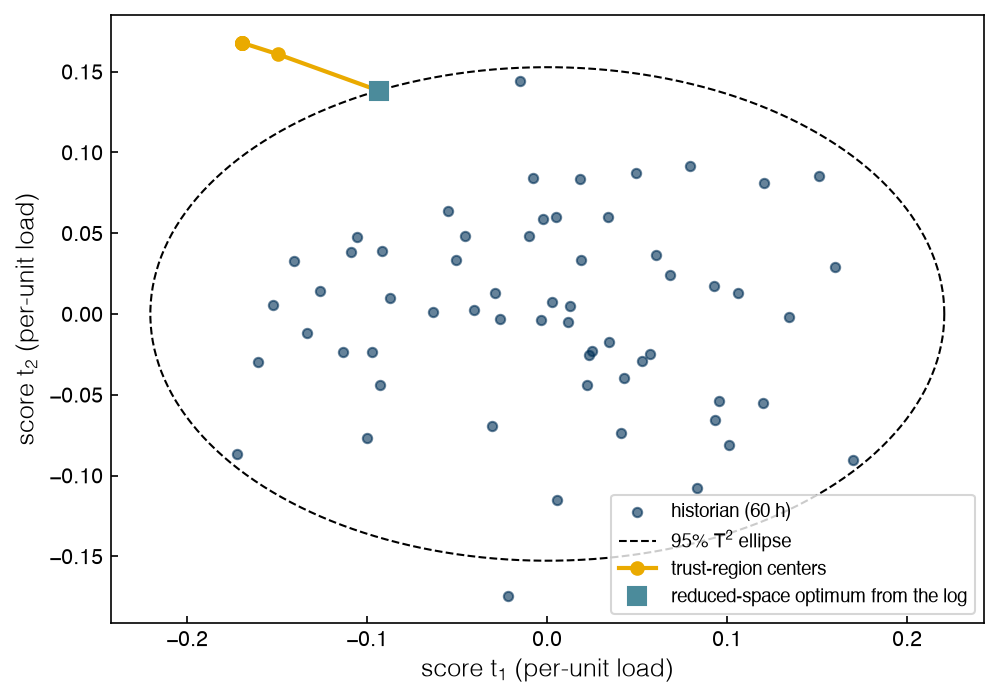

In [9]:
def simulate(t):
    x = fp.inverse_transform(np.atleast_2d(t))[0]       # back-map scores to loads
    return el.bb2(x[:2]), x

hexagon = np.array([[np.cos(a), np.sin(a)] for a in np.arange(6) * np.pi / 3])
tc, radius = res.x.copy(), 0.06
yc, xc = simulate(tc)
n_sim, path = 1, [tc.copy()]
for it in range(12):
    pts = np.vstack([tc, tc + 0.5 * radius * hexagon])           # center + hexagon: 7 points
    ys = np.array([yc] + [simulate(p)[0] for p in pts[1:]])
    n_sim += 6
    b_loc, *_ = np.linalg.lstsq(qf(pts), ys, rcond=None)          # local quadratic, 6 terms
    tn = minimize(lambda t: (qf(t) @ b_loc)[0], tc, method='SLSQP',
                  constraints=[{'type': 'ineq', 'fun': lambda t: radius**2 - ((t - tc)**2).sum()}]).x
    yn, xn = simulate(tn)
    n_sim += 1
    if yn < yc:
        tc, yc, xc, radius = tn, yn, xn, min(2 * radius, 0.2)
    else:
        radius *= 0.5
    path.append(tc.copy())
    print(f"iteration {it + 1:2d}: {n_sim:3d} simulations, loads {np.round(xc, 3)}, cost {yc:.4f}, radius {radius:.4f}")
    if radius < 1e-3:
        break
print(f"final split sums to {xc.sum():.6f}")

grid = [(a, b) for a in np.linspace(0, 1, 201) for b in np.linspace(0, 1, 201)]
costs = np.array([el.bb2(g) for g in grid])
ga, gb = grid[costs.argmin()]
print(f"global optimum of BB2 on a 0.005 grid: cost {costs.min():.4f} at loads ({ga:.3f}, {gb:.3f}, {1.2 - ga - gb:.3f})")

path = np.array(path)
theta = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(Tf[:, 0], Tf[:, 1], s=20, alpha=0.6, label='historian (60 h)')
ax.plot(np.sqrt(T2f * sf2[0]) * np.cos(theta), np.sqrt(T2f * sf2[1]) * np.sin(theta), 'k--', lw=1, label='95% $T^2$ ellipse')
ax.plot(path[:, 0], path[:, 1], 'o-', color='C1', label='trust-region centers')
ax.plot(*res.x, 's', color='C2', ms=9, label='reduced-space optimum from the log')
ax.set_xlabel('score $t_1$ (per-unit load)')
ax.set_ylabel('score $t_2$ (per-unit load)')
ax.legend(fontsize=9);

The loop leaves the ellipse at once and reaches a cost of 2.2291 at (0.374, 0.582, 0.243) after 15 simulations, and the later iterations only shrink the trust region. The historian could not have found this split because the B load of 0.582 is beyond anything in the log (where the largest B load is 0.517), but the split still sums to 1.2 to six digits. This is the interior local optimum of BB2, where all three stacks run.

However, this is not the global optimum. The grid finds a cost of 2.0818 with stack B turned off and A and C at 0.705 and 0.495. A reduced space that is built from data where all of the stacks are on cannot reach that regime, and finding it is the job of the global and mixed-integer methods from earlier in the book ({doc}`../2-nonlinear_mixed_integer/Topic2.6-Non-convex_Problems_and_Bounding`, {doc}`../3-data_driven_optimization/Topic3.6-Surrogate-Based_Optimization`). In general, a reduced space is a model of where the data have been, so it cannot tell us anything about regimes that the data never saw.

The gain from adaptive optimization is small in this case (2.2313 to 2.2291, or 0.1%), because the optimum is flat. Thermodynamically, this means that the losses of the fleet barely change across these splits.

Economically, small gains are worth taking when each trial is safe, and in this case every trial met the demand and stayed close to known operation. In a plant with dozens of correlated variables, this safety is the main argument for optimizing in a reduced space.

:::{exercise}
:label: ex-t42-adaptive-noise

Rerun the adaptive loop with the 0.5% meter noise of the historian added to every simulation (for example `el.bb2(x[:2]) * (1 + 0.005 * rng.standard_normal())`). Does the loop still reach the interior optimum? Replace each evaluation by the mean of four readings and try again. Relate what you see to the noise floor of Topic 4.1.
:::

## Summary

- Undesigned data are usually redundant: their true dimensionality is lower than their number of columns. Feature selection removes variables; dimensionality reduction re-expresses them in fewer new ones.
- PCA is a constrained optimization problem: maximize $p^\top C p$ subject to $p^\top p = 1$. Its KKT conditions are the eigenvalue equation, and the Lagrange multiplier of the unit-length constraint is the variance the component captures.
- Regression on redundant inputs is ill-conditioned. On the modified cheddar data, the full-space quadratic had a condition number of $2 \times 10^8$ and coefficients of $3 \times 10^6$; PCR fitted equally well with a condition number of 8 and predicted better in cross-validation. PLS chooses latent directions that explain the output and did better still.
- Optimizing an ill-conditioned full-space model found a corner of the data box, off the data's plane, with a predicted taste of $10^8$. Optimizing in the reduced space keeps candidates on the plane; write the input bounds as linear constraints on the scores and keep them inside a Hotelling $T^2$ limit.
- A reduced space can encode the constraints the data obeyed. For the electrolyzer fleet, the discarded component was the demand constraint, so every back-mapped split met the demand exactly, and an adaptive trust-region loop in the scores reached the interior optimum of BB2 in 15 simulations. It cannot reach regimes the data never visited, such as switching a stack off.

## Additional Reading

- I. T. Jolliffe, *Principal Component Analysis*, 2nd ed., Springer (2002).
- J. Shlens, "A Tutorial on Principal Component Analysis," arXiv:1404.1100 (2014). The source of the ball-on-a-spring example.
- S. Wold, M. Sjöström and L. Eriksson, "PLS-regression: a basic tool of chemometrics," *Chemometrics and Intelligent Laboratory Systems* 58(2), 109–130 (2001).
- C. M. Jaeckle and J. F. MacGregor, "Product design through multivariate statistical analysis of process data," *AIChE Journal* 44(5), 1105–1118 (1998). Optimization by inverting latent-variable models.
- J. F. MacGregor and T. Kourti, "Statistical process control of multivariate processes," *Control Engineering Practice* 3(3), 403–414 (1995). Hotelling's $T^2$ and the residual in latent-variable monitoring.
- A. R. Conn, K. Scheinberg and L. N. Vicente, *Introduction to Derivative-Free Optimization*, SIAM (2009). Trust-region methods built on local interpolation and regression models.